In [104]:
from pathlib import Path
import matplotlib.pyplot as plt
import csv
import pandas as pd
import numpy as np

In [105]:
results_folder = Path("results")
baseline_folder = results_folder / "baseline"
outfox_folder = results_folder / "outfox_detection" / "google" / "gemma-3-4b-it" / "seed_100"

In [106]:
detector_name_map = {
    "Hello-SimpleAI/chatgpt-detector-roberta": "HC3 (roberta)",
    "roberta-large-openai-detector": "RoBERTa-large",
    "roberta-base-openai-detector": "RoBERTa-base",
}

In [107]:
baseline_result_files = baseline_folder.glob("**/*.csv")
baseline_results_df = None

for file in baseline_result_files:
    df = pd.read_csv(file)
    df["dataset"] = file.stem.replace("_metrics","")
    df["detector"] = detector_name_map[str(file.relative_to(baseline_folder).parent)]

    if baseline_results_df is None:
        baseline_results_df = df
    else:
        baseline_results_df = pd.concat((baseline_results_df, df))

baseline_results_df.head(10)

,metric_name,metric_value,dataset,detector
0,human_rec,72.802198,daigt,RoBERTa-large
1,machine_rec,77.197802,daigt,RoBERTa-large
2,avg_rec,75.000000,daigt,RoBERTa-large
3,accuracy,0.750000,daigt,RoBERTa-large
4,precision,0.739474,daigt,RoBERTa-large
5,recall,0.771978,daigt,RoBERTa-large
6,f1,0.755376,daigt,RoBERTa-large
0,human_rec,75.900277,m4,RoBERTa-large
1,machine_rec,85.872576,m4,RoBERTa-large
2,avg_rec,80.886427,m4,RoBERTa-large


In [108]:
outfox_result_files = outfox_folder.glob("**/*_metrics.csv")
outfox_results_df = None

outfox_detector_name_map = {
    "without_considering_attack": "Without considering attack",
    "with_considering_outfox": "With considering attack",
}

datasets = ["daigt", "m4", "chatgpt", "flan_t5_xxl", "text_davinci_003"]

def find_dataset_name(file_name: str) -> str:
    start_indices = np.array([file_name.find(dataset) for dataset in datasets])
    assert (start_indices > -1).sum() == 1
    start_index = max(start_indices)
    return file_name[start_index:].removesuffix("_metrics")

print(find_dataset_name("with_consdering_outfox_attack_chatgpt_metrics.csv"))

for file in outfox_result_files:
    df = pd.read_csv(file)
    df["dataset"] = find_dataset_name(file.stem)
    df["detector"] = outfox_detector_name_map["_".join(file.stem.split("_", 4)[:3])]

    if outfox_results_df is None:
        outfox_results_df = df
    else:
        outfox_results_df = pd.concat((outfox_results_df, df))

outfox_results_df.head(20)

chatgpt_metrics.csv


,metric_name,metric_value,dataset,detector
0,human_rec,68.600000,chatgpt,Without considering attack
1,machine_rec,77.200000,chatgpt,Without considering attack
2,avg_rec,72.900000,chatgpt,Without considering attack
3,accuracy,0.729000,chatgpt,Without considering attack
4,precision,0.710866,chatgpt,Without considering attack
5,recall,0.772000,chatgpt,Without considering attack
6,f1,0.740173,chatgpt,Without considering attack
0,human_rec,72.400000,chatgpt,With considering attack
1,machine_rec,73.600000,chatgpt,With considering attack
2,avg_rec,73.000000,chatgpt,With considering attack


In [109]:
results_df = pd.concat((baseline_results_df, outfox_results_df))
results_df

,metric_name,metric_value,dataset,detector
0,human_rec,72.802198,daigt,RoBERTa-large
1,machine_rec,77.197802,daigt,RoBERTa-large
2,avg_rec,75.000000,daigt,RoBERTa-large
3,accuracy,0.750000,daigt,RoBERTa-large
4,precision,0.739474,daigt,RoBERTa-large
...,...,...,...,...
2,avg_rec,75.274725,daigt,With considering attack
3,accuracy,0.752747,daigt,With considering attack
4,precision,0.726601,daigt,With considering attack
5,recall,0.810440,daigt,With considering attack


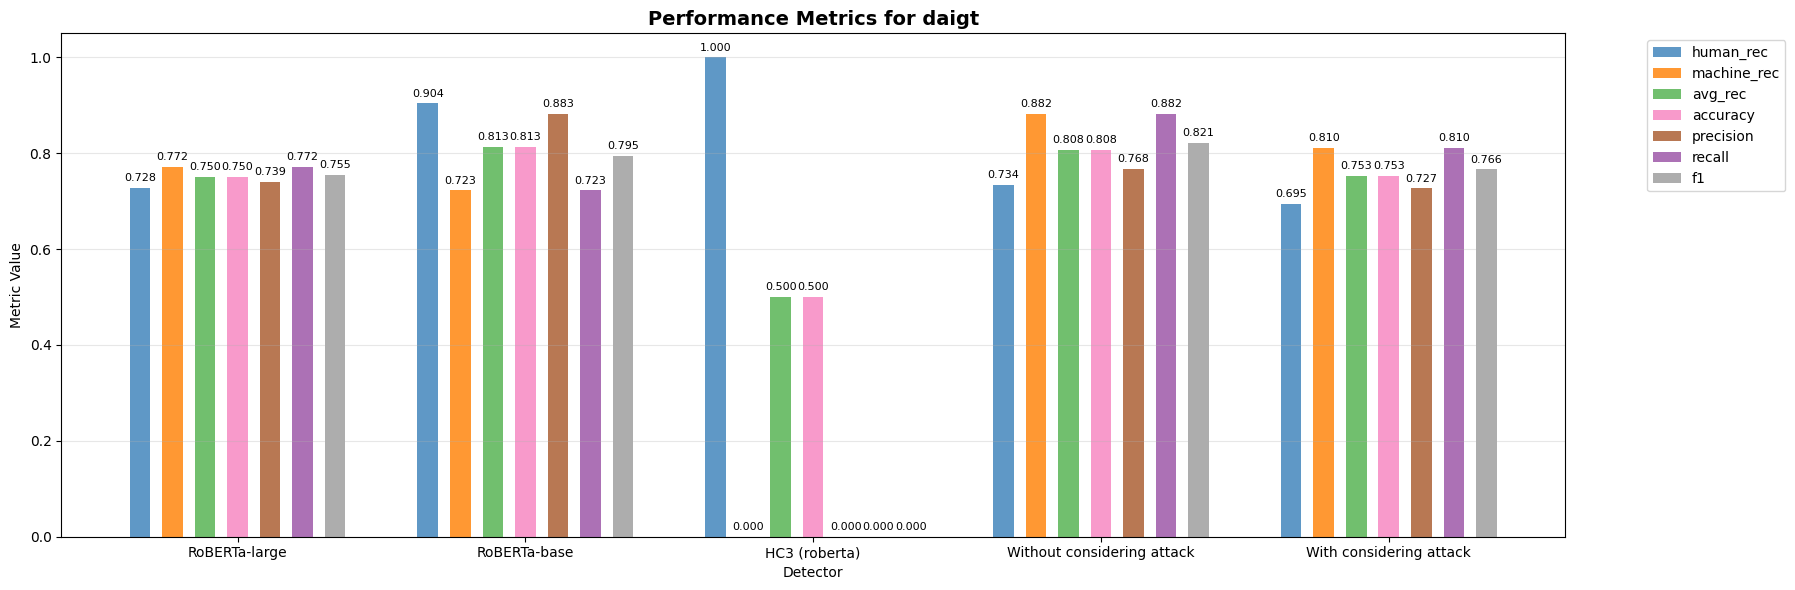

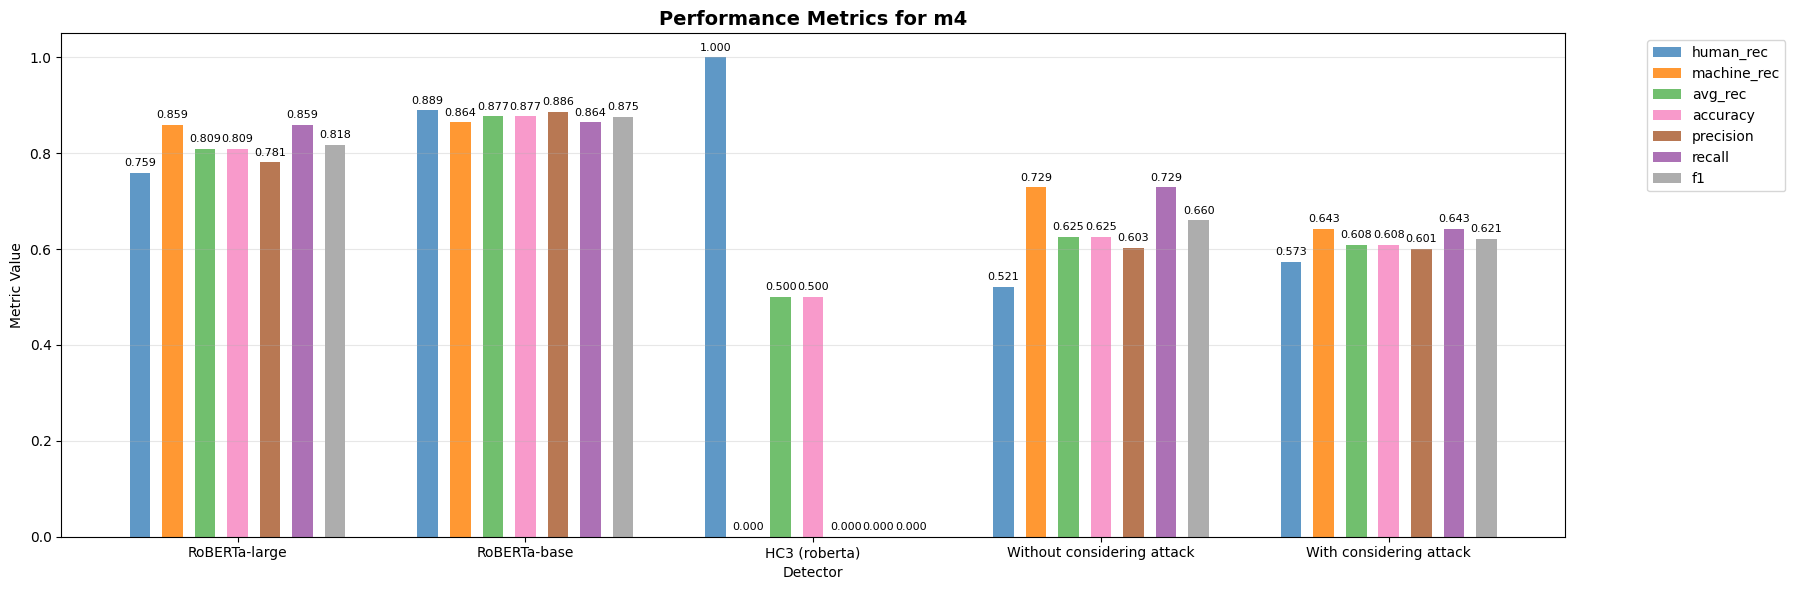

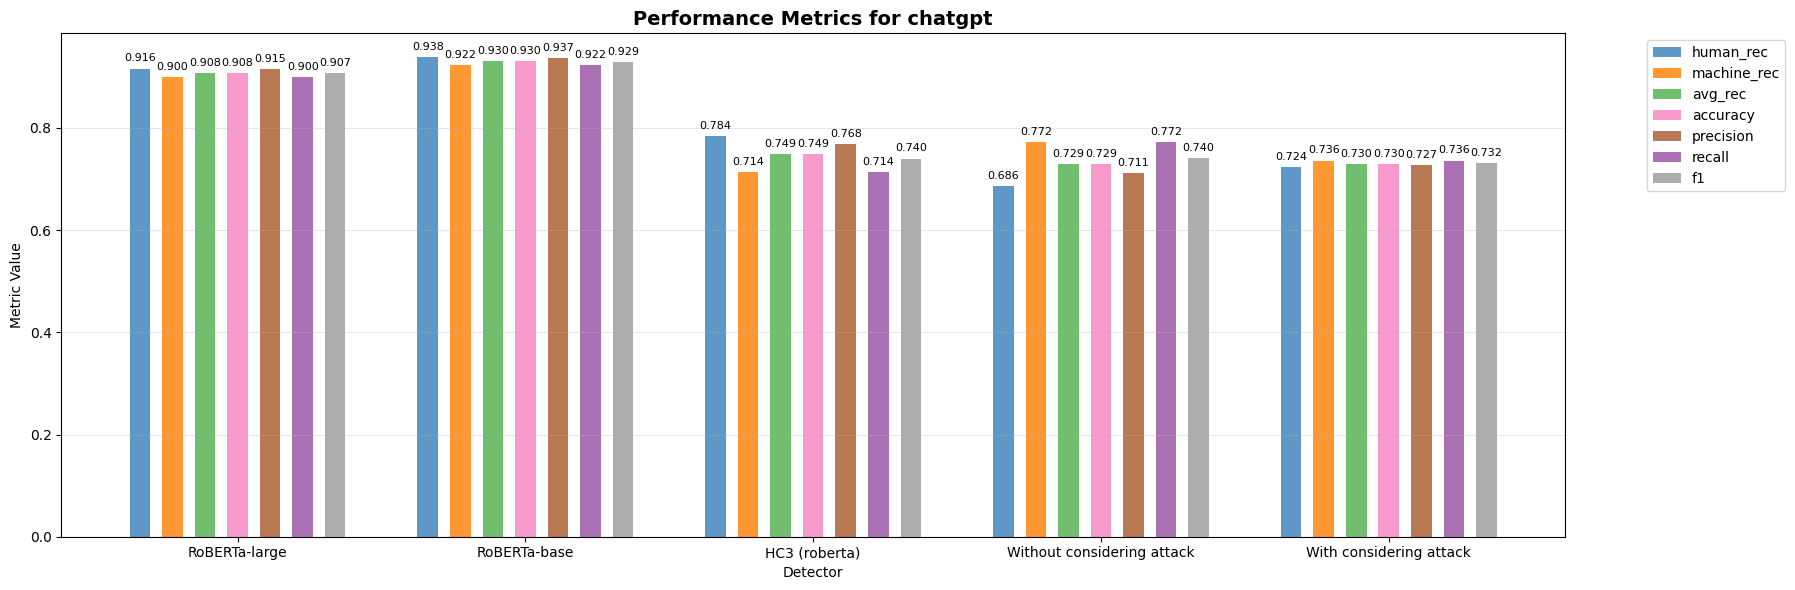

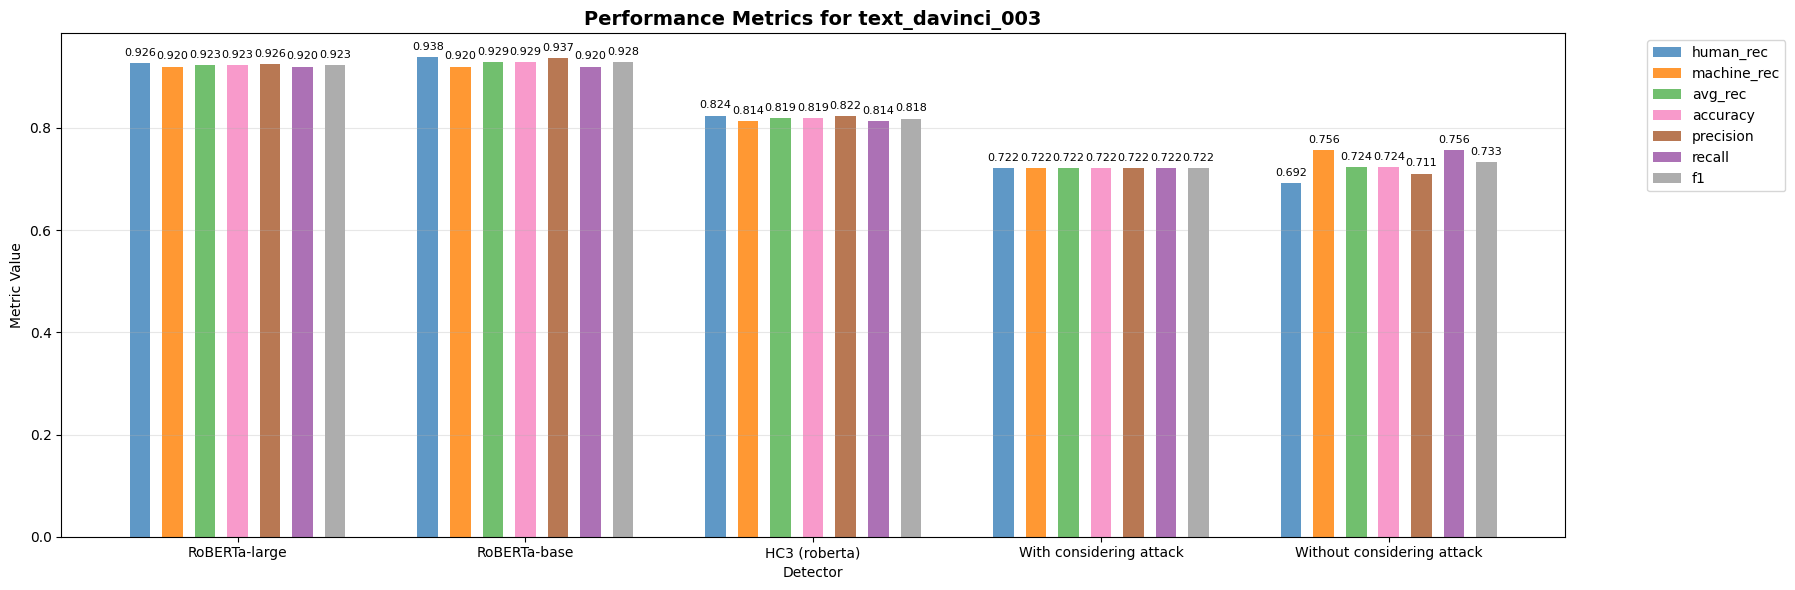

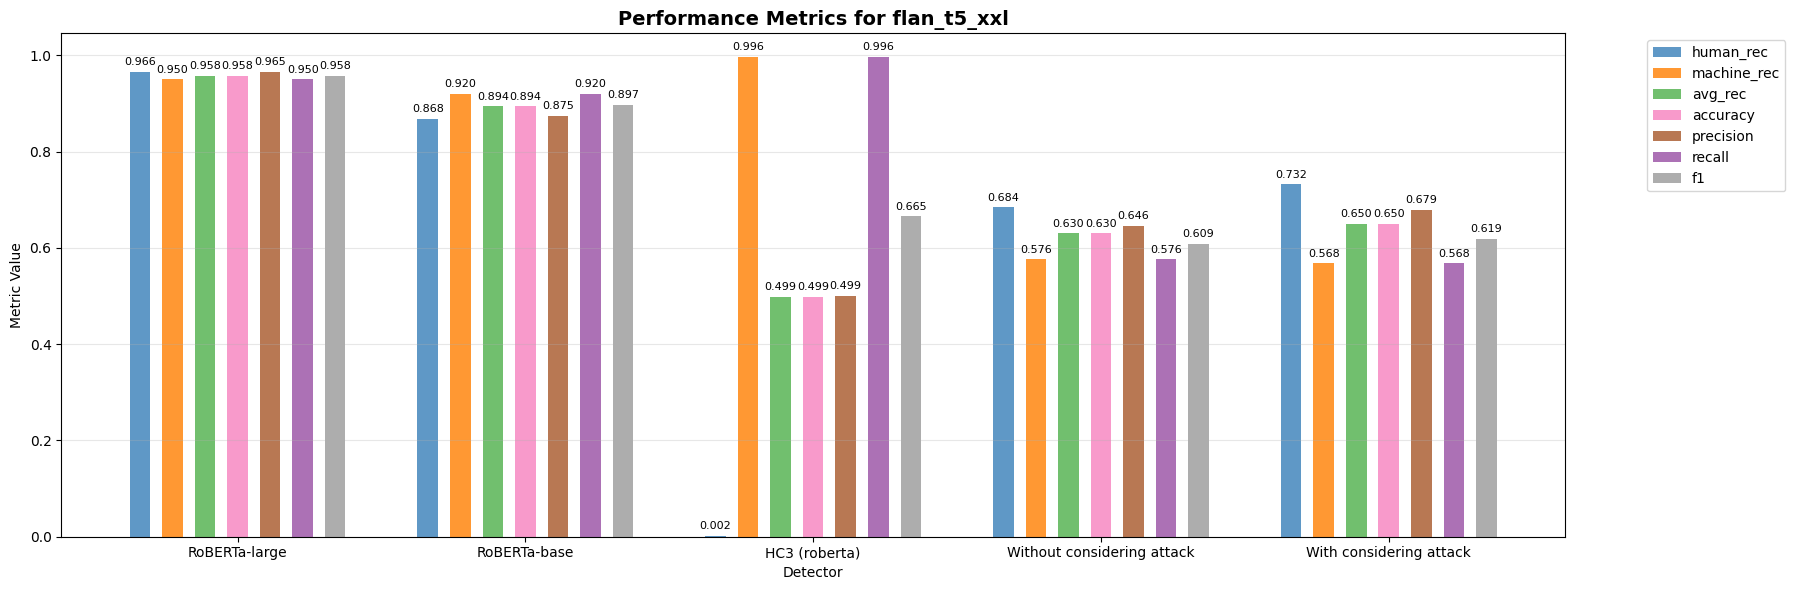

In [110]:
for dataset in results_df["dataset"].unique():
    dataset_results = results_df[results_df["dataset"] == dataset]
    
    # Get unique metrics and detectors
    metrics = dataset_results["metric_name"].unique()
    detectors = dataset_results["detector"].unique()
    
    # Set up the plot
    fig, ax = plt.subplots(figsize=(18, 6))
    
    # Set the width and positions for bars
    n_metrics = len(metrics)
    n_detectors = len(detectors)
    bar_width = 0.6 / n_metrics  # Width of individual bars
    
    # Increase group spacing by adding space between detector positions :cite[3]
    group_spacing = 1.2  # Space between detector groups
    x_pos = np.arange(n_detectors) * group_spacing  # Spread out detector groups
    
    # Define colors for different metrics
    colors = ['#377eb8', '#ff7f00', '#4daf4a',
                  '#f781bf', '#a65628', '#984ea3',
                  '#999999', '#e41a1c', '#dede00']
    
    # Plot bars for each metric
    for i, metric in enumerate(metrics):
        metric_values = []
        for detector in detectors:
            value = dataset_results[
                (dataset_results["metric_name"] == metric) & 
                (dataset_results["detector"] == detector)
            ]["metric_value"].values
            if metric in ["human_rec", "machine_rec", "avg_rec"]:
                value /= 100
            metric_values.append(value[0] if len(value) > 0 else 0)
        
        # Calculate positions for this metric's bars with small spacing between metrics :cite[7]
        metric_spacing = 0.05  # Small space between metrics within same detector
        positions = x_pos + i * (bar_width + metric_spacing) - (n_metrics - 1) * (bar_width + metric_spacing) / 2
        
        # Create bars
        bars = ax.bar(positions, metric_values, bar_width, 
                     label=metric, color=colors[i], alpha=0.8)
        
        # Add value labels on top of bars
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{height:.3f}', ha='center', va='bottom', fontsize=8)
    
    # Customize the plot
    ax.set_title(f'Performance Metrics for {dataset}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Detector')
    ax.set_ylabel('Metric Value')
    ax.set_xticks(x_pos)
    
    ax.set_xticklabels(detectors, rotation=0, ha='center')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()